## Before running: paths, timing caches, and output replacement

See the [raw-to-RF guide](README.md) and [platform and data-safety notes](docs/platforms_and_data_safety.md). Start this kernel in the repository directory so `./file_names.json` resolves. Change `base_dir`, recording identifiers, probe, and headplate to your data; `/mnt/...` is an example Linux mount. On native Windows use a raw string such as `r"D:\recordings\mouse_01"`; on macOS/Linux use the actual mounted path. Preserve directory capitalization.

- With the supplied `file_names.json`, the preprocessing caches are `data/session_info.json`, `data/sync_data.json`, and `data/interval_table.csv`. Copied `session_info.json` can retain another machine's `session_info["base_path"]` and `session_name`; inspect those paths after moving data. Changing only `base_dir` does not rewrite this cache.
- The current `gen_recording_interval_table(...)` call leaves `is_overwrite_interval_table`, `is_overwrite_session_file`, and `is_overwrite_sync_file` at `False`. An existing interval table skips the generator entirely. Changing a session/sync overwrite flag alone therefore does not regenerate it. Preserve existing files and any edited interval table before deliberately regenerating the specific derived cache; do not delete a timing-edit database to fix a path.
- Camera timing uses `data/camera_frame_times.npy` first, then saved midpoint data in `data/sync_data.json`, then raw ADC. Check `ttl_qc["source_path"]`; changing channel settings does not invalidate saved timing.
- `is_save=True` replaces `data/tuning_curves/ProbeA/tuning_curves.tc` and the exact-class unit lists `hd_cells_1.npy`, `hd_cells_2.npy`, and `hd_cells_3.npy` for the chosen probe. Use `is_save=False` for calculation without those final writes, or supply `save_path` in a new directory to preserve the curve and unit lists. Preprocessing can still create missing caches when final-result saving is disabled.
- With saving enabled, also prepare `data/tc_comparison/hd_class3_ProbeA.csv` for the chosen probe: 30 bins, no smoothing, and explicit mouse/date/probe unit IDs. Existing comparison CSVs are left unchanged.
- HD Class 3 requires Rayleigh p ≤ 0.01, shuffle p ≤ 0.01, and von Mises κ ≥ 0.075. Class 2 contains the remaining units passing both significance tests. κ uses the normalized, occupancy-corrected 180-bin rate curve without smoothing or baseline subtraction.


In [1]:
import sys
from pathlib import Path

print("Python:", sys.executable)
print("Project folder:", Path.cwd())

import numpy
import pandas
import scipy
import matplotlib
import pynapple
import tqdm

print("Basic analysis packages imported successfully.")

Python: r:\Basic_Sciences\Phys\SenzaiLab\Aparna\Projects\360-RF-mapping\rfmapping\.venv\Scripts\python.exe
Project folder: r:\Basic_Sciences\Phys\SenzaiLab\Aparna\Projects\360-RF-mapping\rfmapping
Basic analysis packages imported successfully.


In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from tqdm import tqdm
import numpy as np
import pandas as pd

from Utils.load_files import get_interval_pairs
from Utils.json_tools import read_formatted_json
from Utils.tuning_curve_utils import get_exposure_timestamps, make_head_direction_tsd, tuning_curve
from Utils.recording import gen_recording_interval_table
from Utils.tc_preparation import prepare_hd_tc

file_names = read_formatted_json("./file_names.json")
session_info_filename: str = file_names["session_info_filename"]
head_direction_filename: str = file_names["head_direction_filename"]
interval_table_filename: str = file_names["interval_table_filename"]
kilosort_info_filename: str = file_names["kilosort_info_filename"]


Matplotlib is building the font cache; this may take a moment.


In [3]:
day_dir = Path(
    r"R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse"
    r"\m002\small-spread-neuropixel-config\2026-09-25"
)

sessions_dir = day_dir / "ad_session_2026_09_25" / "sessions"

for folder in sorted(sessions_dir.glob("session_*")):
    with np.load(folder / "session_info.npz", allow_pickle=False) as info:
        print(folder.name, "→", info["session_name"].item())

session_01 → free-360-landmarks
session_02 → free-360-stars
session_03 → free-openfield
session_04 → head-fixed-360-RF
session_05 → head-fixed-360-stars


In [4]:
split_session_dir = sessions_dir / "session_01"
neural_dir = split_session_dir / "neural" / "ProbeA"

recording_dir = day_dir / "20260925_Free-360-withLandmarks"
motive_run_dir = recording_dir / "motive-results" / "20261009_153505"
hd_path = motive_run_dir / "processed" / "head_direction.json"

files = {
    "Motive head direction": hd_path,
    "Motive configuration": motive_run_dir / "config" / "config_used.yaml",
    "Spike timestamps": neural_dir / "adc_spike_times.npy",
    "Spike cluster IDs": neural_dir / "spike_clusters.npy",
    "Unit labels": neural_dir / "cluster_KSLabel.tsv",
}

for label, path in files.items():
    print(f"{label}: {'FOUND' if path.is_file() else 'MISSING'}")

Motive head direction: FOUND
Motive configuration: FOUND
Spike timestamps: FOUND
Spike cluster IDs: FOUND
Unit labels: FOUND


In [5]:
raw_recording_dir = recording_dir / "AD_2026-09-25_13-55-35"

oebin_paths = sorted(raw_recording_dir.rglob("structure.oebin"))

print("Recording metadata files:")
for path in oebin_paths:
    print(path)

print("\nExisting camera timestamps:")
for folder in (recording_dir, split_session_dir):
    for path in folder.rglob("camera_frame_times.npy"):
        print(path)

Recording metadata files:
R:\Basic_Sciences\Phys\SenzaiLab\Aparna\Data_by_mouse\m002\small-spread-neuropixel-config\2026-09-25\20260925_Free-360-withLandmarks\AD_2026-09-25_13-55-35\Record Node 102\experiment1\recording1\structure.oebin

Existing camera timestamps:


In [6]:
import json

oebin_path = oebin_paths[0]

with oebin_path.open() as f:
    recording_metadata = json.load(f)

for stream in recording_metadata.get("continuous", []):
    print("Folder:", stream.get("folder_name"))
    print("Sample rate:", stream.get("sample_rate"))
    print("Channels:", stream.get("num_channels"))
    for channel in stream.get("channels", []):
        print("  ", channel.get("channel_name"))
    print()

Folder: OneBox-104.ProbeA/
Sample rate: 30000.0
Channels: 384
   CH0
   CH1
   CH2
   CH3
   CH4
   CH5
   CH6
   CH7
   CH8
   CH9
   CH10
   CH11
   CH12
   CH13
   CH14
   CH15
   CH16
   CH17
   CH18
   CH19
   CH20
   CH21
   CH22
   CH23
   CH24
   CH25
   CH26
   CH27
   CH28
   CH29
   CH30
   CH31
   CH32
   CH33
   CH34
   CH35
   CH36
   CH37
   CH38
   CH39
   CH40
   CH41
   CH42
   CH43
   CH44
   CH45
   CH46
   CH47
   CH48
   CH49
   CH50
   CH51
   CH52
   CH53
   CH54
   CH55
   CH56
   CH57
   CH58
   CH59
   CH60
   CH61
   CH62
   CH63
   CH64
   CH65
   CH66
   CH67
   CH68
   CH69
   CH70
   CH71
   CH72
   CH73
   CH74
   CH75
   CH76
   CH77
   CH78
   CH79
   CH80
   CH81
   CH82
   CH83
   CH84
   CH85
   CH86
   CH87
   CH88
   CH89
   CH90
   CH91
   CH92
   CH93
   CH94
   CH95
   CH96
   CH97
   CH98
   CH99
   CH100
   CH101
   CH102
   CH103
   CH104
   CH105
   CH106
   CH107
   CH108
   CH109
   CH110
   CH111
   CH112
   CH113
   CH114
   CH115
   C

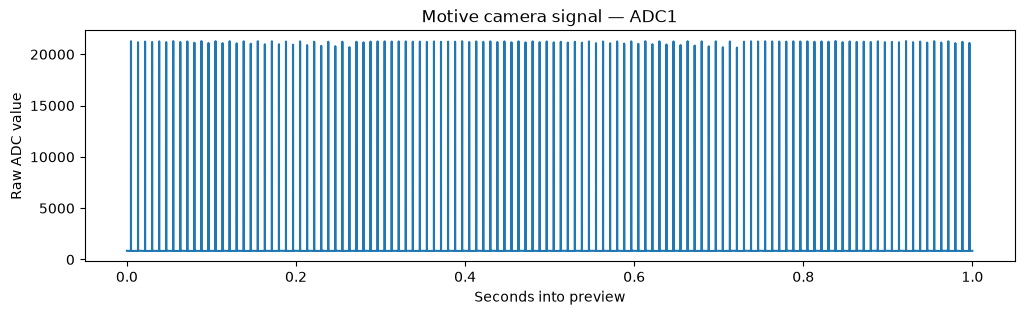

In [7]:
import matplotlib.pyplot as plt

adc_stream = next(
    stream for stream in recording_metadata["continuous"]
    if "OneBox-ADC" in stream["folder_name"]
)

adc_dir = oebin_path.parent / "continuous" / adc_stream["folder_name"]
adc_fs = float(adc_stream["sample_rate"])
n_channels = int(adc_stream["num_channels"])

adc_data = np.memmap(
    adc_dir / "continuous.dat",
    dtype=np.int16,
    mode="r",
).reshape(-1, n_channels)

# Preview one second, starting 10 seconds into the recording.
start = int(10 * adc_fs)
stop = min(start + int(adc_fs), len(adc_data))
signal = adc_data[start:stop, 1]

plt.figure(figsize=(12, 3))
plt.plot(np.arange(len(signal)) / adc_fs, signal)
plt.xlabel("Seconds into preview")
plt.ylabel("Raw ADC value")
plt.title("Motive camera signal — ADC1")
plt.show()

In [8]:
camera_input_channel = 1
camera_pulse_threshold = 11000

rise_indices = []
previous_high = False
chunk_size = 1_000_000

for start in tqdm(range(0, len(adc_data), chunk_size)):
    signal_chunk = adc_data[
        start:start + chunk_size, camera_input_channel
    ]
    high = signal_chunk > camera_pulse_threshold

    rising = high & ~np.r_[previous_high, high[:-1]]
    rise_indices.append(start + np.flatnonzero(rising))
    previous_high = bool(high[-1])

camera_frame_indices = np.concatenate(rise_indices)

hd_content = read_formatted_json(hd_path)
motive_frames = np.asarray(hd_content["hp4"]["frames"], dtype=int)

print("Camera pulses:", len(camera_frame_indices))
print("Motive frames:", len(motive_frames))
print("First / last Motive frame:", motive_frames[0], motive_frames[-1])
print(
    "Motive frames continuous from zero:",
    np.array_equal(motive_frames, np.arange(len(motive_frames))),
)

100%|██████████| 72/72 [00:28<00:00,  2.49it/s]


Camera pulses: 280010
Motive frames: 280011
First / last Motive frame: 0 280010
Motive frames continuous from zero: True


In [9]:
adc_timestamps = np.load(adc_dir / "timestamps.npy", mmap_mode="r")
camera_frame_times = np.asarray(
    adc_timestamps[camera_frame_indices], dtype=float
)

frame_intervals = np.diff(camera_frame_times)
median_interval = np.median(frame_intervals)

print(f"Typical frame interval: {median_interval * 1000:.3f} ms")
print(f"Typical frame rate: {1 / median_interval:.2f} Hz")
print(f"Largest frame interval: {frame_intervals.max() * 1000:.3f} ms")
print("Gaps > 1.5 × typical interval:",
      np.count_nonzero(frame_intervals > 1.5 * median_interval))
print("Intervals all positive:", np.all(frame_intervals > 0))

Typical frame interval: 8.349 ms
Typical frame rate: 119.78 Hz
Largest frame interval: 8.381 ms
Gaps > 1.5 × typical interval: 0
Intervals all positive: True


In [10]:
with np.load(
    split_session_dir / "session_info.npz",
    allow_pickle=False,
) as info:
    for key in (
        "session_name",
        "adc_global_start_s",
        "adc_global_end_s",
    ):
        print(key, ":", info[key].item())

spike_times = np.load(
    neural_dir / "adc_spike_times.npy",
    mmap_mode="r",
)

print("Raw ADC first timestamp:", float(adc_timestamps[0]))
print("Raw ADC last timestamp:", float(adc_timestamps[-1]))
print("First camera pulse:", camera_frame_times[0])
print("Last camera pulse:", camera_frame_times[-1])
print("Split spike time range:", float(spike_times.min()),
      "to", float(spike_times.max()))

session_name : free-360-landmarks
adc_global_start_s : 0.0
adc_global_end_s : 2343.186465994151
Raw ADC first timestamp: 128.8898971206016
Raw ADC last timestamp: 2472.0763301119973
First camera pulse: 132.07763781330343
Last camera pulse: 2465.3349746363
Split spike time range: 0.0005747456447506849 to 2343.1860971180417


In [11]:
# Convert raw camera timestamps to session-local seconds.
camera_times_local = camera_frame_times - float(adc_timestamps[0])

hd_angles = np.asarray(
    hd_content["hp4"]["head_direction_deg"], dtype=float
)

# Follow Kai's rule for one extra trailing Motive frame.
assert len(motive_frames) == len(camera_times_local) + 1
assert len(hd_angles) == len(motive_frames)

aligned_frames = motive_frames[:-1]
aligned_hd_angles = hd_angles[:-1]

print("Aligned frames:", len(aligned_frames))
print(
    "Tracking interval:",
    f"{camera_times_local[0]:.3f} to "
    f"{camera_times_local[-1]:.3f} seconds",
)
print("Head-angle values:", len(aligned_hd_angles))

Aligned frames: 280010
Tracking interval: 3.188 to 2336.445 seconds
Head-angle values: 280010


In [ ]:
base_dir = r"/mnt/senzailab/Kai/#Recording/m14"

date: str | int = "260609"
multi_recording: bool = True
num_of_rec_list: list[int] = [1, ]
headplate_name: str = 'hp4'
probe_name: str = "A"

phase_key = "baseline"
num_of_bins_in_hd: int = 180
num_shuffle: int = 1000
shuffle_seed: int = 0
kappa_cutoff: float = 0.1

camera_input_channel: int = 1
is_save: bool = True

for num_of_rec in num_of_rec_list:

    with tqdm(total=5, desc="Reading files", unit="%",
              bar_format="{l_bar}{bar}| {n}/{total} [{percentage:3.0f}%]") as pbar:
        subfolder_filler = f"{date}_{num_of_rec}"
        session_dir = f"{base_dir}/{date}/{subfolder_filler}" if multi_recording else f"{base_dir}/{date}"

        gen_recording_interval_table(base_dir=session_dir, multi_recording=multi_recording,
                                     camera_input_channel=camera_input_channel, )

        data_dir: str = f"{session_dir}/data"
        kilosort_dir = next((Path(session_dir) / "kilosort" / f"Probe{probe_name}").glob("kilosort_*"))

        session_info: dict = read_formatted_json(f"{data_dir}/{session_info_filename}.json")["session_info"]
        pbar.update(1)

        interval_table = pd.read_csv(f"{data_dir}/{interval_table_filename}.csv")
        interval_pairs_all = np.asarray(
            get_interval_pairs(interval_table,
                               phase_key=phase_key), dtype=float)
        pbar.update(1)

        hd_content = read_formatted_json(f"{data_dir}/processed/{head_direction_filename}.json")
        hd_raw = hd_content[headplate_name].get('head_direction_deg')
        hd = np.asarray(hd_raw, dtype=float)
        hd = hd % 360
        hd_frames = np.asarray(hd_content[headplate_name].get('frames'), dtype=int)
        pbar.update(1)

        exposure_timestamps, adc_time_origin_s, ttl_qc = get_exposure_timestamps(
            session_info=session_info,
            data_dir=data_dir,
        )
        pbar.update(1)

        assert np.array_equal(hd_frames, np.arange(len(hd_frames))), (
            "Motive frame IDs must be zero-based and continuous."
        )

        if len(hd_frames) == len(exposure_timestamps) + 1:
            print(f"Dropping trailing Motive frame: {hd_frames[-1]}")
            hd = hd[:-1]
            hd_frames = hd_frames[:-1]
        elif len(hd_frames) != len(exposure_timestamps):
            raise ValueError(
                f"Motive frame/TTL count mismatch: {len(hd_frames)} frames vs {len(exposure_timestamps)} exposure pulses.")

        assert len(hd) == len(hd_frames)

        # head_direction.json must already use the GUI convention: 0 degrees up,
        # positive counter-clockwise. This notebook only applies modulo 360.
        HD_tsd, feature_fs_hz = make_head_direction_tsd(exposure_timestamps, hd_frames, hd)
        ttl_qc["motive_frame_count"] = int(len(hd_frames))
        pbar.update(1)

    interval_pairs = interval_pairs_all[[0]]

    hd_tuning_curves_A_formatted = tuning_curve(base_dir=session_dir,
                                                kilosort_dir=kilosort_dir,
                                                probe_name=probe_name,
                                                interval_pairs=interval_pairs,
                                                HD_tsd=HD_tsd,
                                                adc_time_origin_s=adc_time_origin_s,
                                                num_of_bins_in_hd=num_of_bins_in_hd,
                                                num_shuffle=num_shuffle,
                                                shuffle_seed=shuffle_seed,
                                                kappa_cutoff=kappa_cutoff,
                                                is_save=is_save,
                                                feature_fs_hz=feature_fs_hz,
                                                metadata={
                                                    "epoch": phase_key,
                                                    "headplate": headplate_name,
                                                    "ttl_qc": ttl_qc,
                                                },
                                                )

    if is_save:
        prepare_hd_tc(
            Path(data_dir) / "tuning_curves" / f"Probe{probe_name}" / "tuning_curves.tc",
            Path(data_dir) / "tc_comparison" / f"hd_class3_Probe{probe_name}.csv",
            bins=30, hd_class=3, unit_prefix=f"{Path(base_dir).name}:{date}:{probe_name}",
        )
